# Pregunta 3 - Monitoreo de fauna con camaras trampa (YOLO)
Ejecuta las celdas **en orden**. Runtime > Change runtime type > **GPU (T4)**.
Todo lo pesado (descarga, entrenamiento) corre aqui; los resultados se guardan en tu Google Drive para no perderlos si Colab se desconecta.

## 0. GPU y Drive

In [7]:
!nvidia-smi -L
from google.colab import drive
drive.mount('/content/drive')
import os
os.makedirs('/content/drive/MyDrive/cct_yolo_out', exist_ok=True)

GPU 0: NVIDIA A100-SXM4-80GB (UUID: GPU-4bdfedf3-a010-f540-af43-6f6c6aef51ac)
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
REPO_URL = 'https://github.com/SalvadorCT/cct-yolo.git'
import os, subprocess
os.chdir('/content')
if REPO_URL:
    !git clone {REPO_URL} cct_yolo
else:
    !unzip -q -o /content/drive/MyDrive/cct_yolo.zip -d /content/
%cd /content/cct_yolo
os.environ['PYTHONPATH'] = '/content/cct_yolo/src'   # para que funcione `python -m cct.*`
!pip install -q -r requirements.txt

Cloning into 'cct_yolo'...
remote: Enumerating objects: 34, done.
remote: Counting objects: 100% (34/34), done.
remote: Compressing objects: 100% (31/31), done.
remote: Total 34 (delta 0), reused 34 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (34/34), 48.37 KiB | 3.45 MiB/s, done.
/content/cct_yolo


## 2. Descarga de datos (LILA BC)
`metadata` pesa poco. `images` baja ~6 GB (CCT20, imagenes a 1024 px)

## 1. Codigo del repo
Opcion A : clona tu repo de GitHub. Opcion B: sube `cct_yolo.zip` a `MyDrive/` y se descomprime.

In [3]:
!python -m cct.download --what metadata
!python -m cct.download --what images
!ls data/raw | head

Metadatos...
  bajando https://storage.googleapis.com/public-datasets-lila/caltechcameratraps/labels/caltech_bboxes_20200316.json
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 36.3M  100 36.3M    0     0  21.7M      0  0:00:01  0:00:01 --:--:-- 21.7M
  bajando https://storage.googleapis.com/public-datasets-lila/caltechcameratraps/CaltechCameraTrapsSplits_v0.json
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  4122  100  4122    0     0  24166      0 --:--:-- --:--:-- --:--:-- 24247
  bajando https://storage.googleapis.com/public-datasets-lila/caltechcameratraps/labels/caltech_camera_traps.json.zip
  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 88

## 3. Revisar el JSON de splits
Confirma que `eccv_train` y `eccv_val` aparecen y son listas de ubicaciones (si la estructura es otra, el constructor la imprime).

In [4]:
import json
d = json.load(open('data/raw/CaltechCameraTrapsSplits_v0.json'))
def brief(n, depth=0):
    if isinstance(n, dict): return {k: brief(v, depth+1) for k, v in list(n.items())[:12]} if depth < 3 else '{...}'
    if isinstance(n, list): return f'list[{len(n)}] {n[:5]}'
    return n
print(json.dumps(brief(d), indent=1)[:1500])

{
 "info": {
  "version": "1.0",
  "description": "Train/val splits for Caltech Camera Traps"
 },
 "splits": {
  "train": "list[120] ['10', '102', '103', '106', '107']",
  "val": "list[40] ['0', '1', '100', '101', '104']",
  "eccv_train": "list[30] ['33', '33', '33', '38', '38']",
  "eccv_val": "list[10] ['0', '7', '28', '40', '46']"
 }
}


## 4. Construir el dataset YOLO (train / val / test_seen / test_unseen)

In [5]:
!python -m cct.build_dataset --config configs/config.yaml
!cat data/yolo/stats.json | head -40

Leyendo anotaciones...
AVISO: no hay image_json; se asume vacia toda imagen del JSON de cajas sin anotaciones.
Splits (listas): 10 ubicaciones eccv_train, 10 eccv_val
Imagenes encontradas en disco: 57864
Con animal por subconjunto: {'train': 20504, 'test_unseen': 18878, 'val': 2760, 'test_seen': 2727} | sin archivo: 0
Vacias disponibles: {'train': 352, 'test_unseen': 619, 'val': 52, 'test_seen': 57}
Clases (15): ['opossum', 'raccoon', 'squirrel', 'bobcat', 'skunk', 'dog', 'coyote', 'rabbit', 'bird', 'cat', 'badger', 'car', 'deer', 'fox', 'rodent']

Resumen:
{
 "classes": [
  "opossum",
  "raccoon",
  "squirrel",
  "bobcat",
  "skunk",
  "dog",
  "coyote",
  "rabbit",
  "bird",
  "cat",
  "badger",
  "car",
  "deer",
  "fox",
  "rodent"
 ],
 "images": {
  "test_seen": 2784,
  "test_unseen": 19497,
  "train": 20856,
  "val": 2812
 },
 "images_empty": {
  "test_seen": 57,
  "test_unseen": 619,
  "train": 352,
  "val": 52
 },
 "locations": {
  "test_seen": 10,
  "test_unseen": 10,
  "train

Si `stats.json` muestra muy pocas imagenes vacias, descarga extras: `!python -m cct.download --what metadata --fetch-empties 3000` y repite el paso 4.

## 5. Entrenamiento (entregable 1)
~30 epocas con YOLOv8s a 640 px. Los pesos y `decisions.json` se guardan en Drive. Si Colab se corta, repite los pasos 0-4 (los datos se vuelven a bajar) y reanuda con `--set train.model=<ruta a last.pt en Drive>` (arranca desde esos pesos con el mismo nombre de corrida).

In [11]:
RUNS = '/content/drive/MyDrive/cct_yolo_out/runs'
!python -m cct.train --config configs/config.yaml --set paths.runs={RUNS} train.epochs=30 train.workers=4 train.batch=32

Ultralytics 8.4.193 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/cct_yolo/data/yolo/data.yaml, degrees=5.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_640_strong, nbs=64, nms=None, op

## 6. Evaluacion por especie (entregable 2)

In [13]:
W = f'{RUNS}/yolov8s_640_strong/weights/best.pt'
REP = '/content/drive/MyDrive/cct_yolo_out/reports'
!python -m cct.evaluate --config configs/config.yaml --weights {W} --set paths.reports={REP} paths.runs={RUNS}
import pandas as pd
display(pd.read_csv(f'{REP}/tables/summary.csv'))

inferencia: 100% 87/87 [00:32<00:00,  2.71it/s]
[test_seen] mAP50=0.841  mAP50-95=0.593
inferencia: 100% 610/610 [03:18<00:00,  3.08it/s]
[test_unseen] mAP50=0.462  mAP50-95=0.314
     subset  n_images  n_boxes    map50  map5095  spearman_logn_ap50  n_empty  frac_with_fp  fp_per_image
  test_seen      2784     2878 0.841192 0.592930            0.389286       57      0.964912      1.105263
test_unseen     19497    19673 0.462331 0.314407            0.696703      619      0.940226      1.226171


,subset,n_images,n_boxes,map50,map5095,spearman_logn_ap50,n_empty,frac_with_fp,fp_per_image
0,test_seen,2784,2878,0.841192,0.592930,0.389286,57,0.964912,1.105263
1,test_unseen,19497,19673,0.462331,0.314407,0.696703,619,0.940226,1.226171


## 7. Generalizacion: ubicaciones vistas vs nuevas + Grad-CAM (entregable 3)

       metrica   vistas   nuevas  brecha_abs  caida_relativa_pct
         map50 0.841192 0.462331    0.378860           45.038530
       map5095 0.592930 0.314407    0.278523           46.974067
recall_at_conf 0.935719 0.738728    0.196991           21.052366
  frac_with_fp 0.964912 0.940226    0.024686            2.558379
     subset  n  energia_en_caja  area_caja  detecta_original  detecta_tras_enmascarar  energia_sobre_area
  test_seen 24         0.136728   0.133991          1.000000                 0.041667            1.020425
test_unseen 24         0.111508   0.188173          0.833333                 0.000000            0.592583
Listo: reports/tables/generalization_*.csv y reports/figures/gradcam_seen_vs_unseen.png


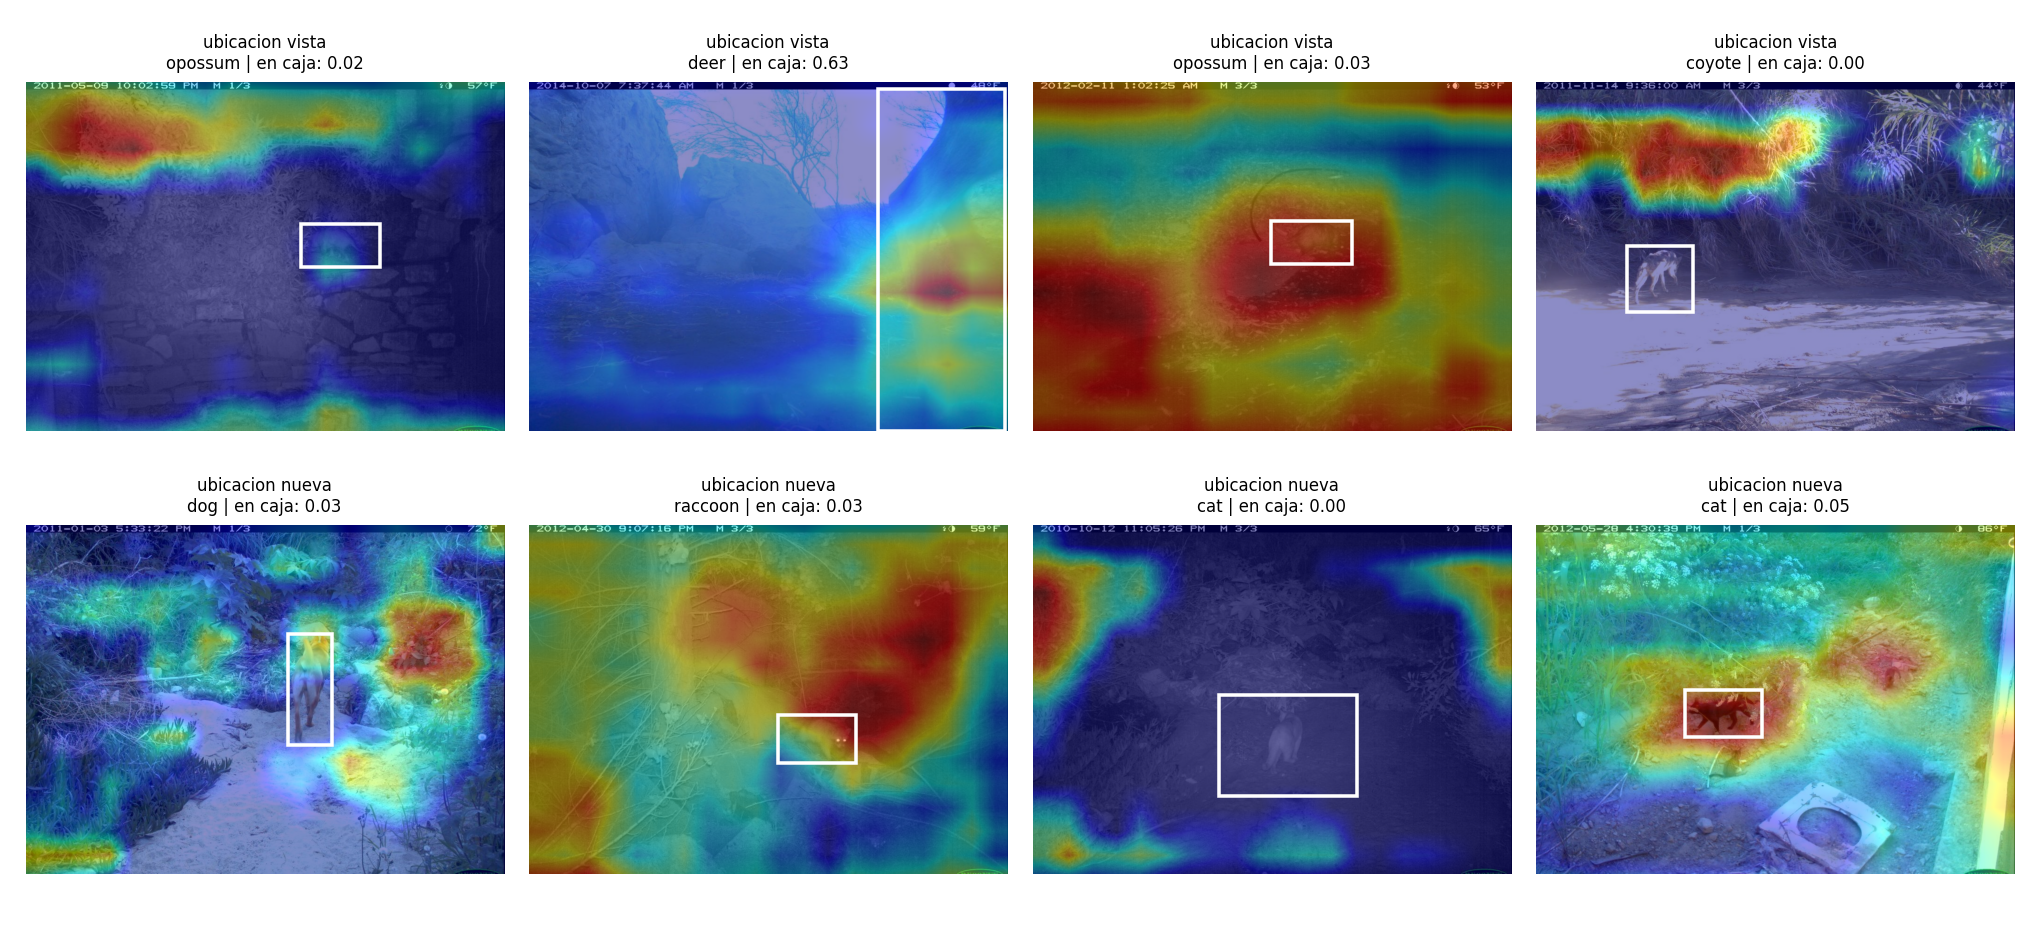

,metrica,vistas,nuevas,brecha_abs,caida_relativa_pct
0,map50,0.841192,0.462331,0.378860,45.038530
1,map5095,0.592930,0.314407,0.278523,46.974067
2,recall_at_conf,0.935719,0.738728,0.196991,21.052366
3,frac_with_fp,0.964912,0.940226,0.024686,2.558379


,subset,n,energia_en_caja,area_caja,detecta_original,detecta_tras_enmascarar,energia_sobre_area
0,test_seen,24,0.136728,0.133991,1.000000,0.041667,1.020425
1,test_unseen,24,0.111508,0.188173,0.833333,0.000000,0.592583


In [14]:
!python -m cct.generalization --config configs/config.yaml --weights {W} --set paths.reports={REP} paths.runs={RUNS}
from IPython.display import Image, display
display(Image(f'{REP}/figures/gradcam_seen_vs_unseen.png'))
display(pd.read_csv(f'{REP}/tables/generalization_drop.csv'))
display(pd.read_csv(f'{REP}/tables/generalization_gradcam_summary.csv'))

## 8. Robustez: oclusion y tamano (entregable 4)
Antes (opcional pero recomendado) valida el proxy de oclusion con etiquetas manuales: genera la plantilla, rellena ~60 filas (1 = visible, 2 = parcial, 3 = muy tapado) y corre `--validate`.

test_seen 
   grupo  n_cajas    map50  map5095  recall_conf
pequena      838 0.700126 0.365602     0.861575
mediana      969 0.864311 0.551397     0.960784
 grande     1071 0.790298 0.587055     0.971055 
 grupo  n_cajas    map50  map5095  recall_conf
 baja      960 0.785918 0.559409     0.938542
media      958 0.871142 0.570190     0.949896
 alta      960 0.874010 0.559469     0.918750
test_unseen 
   grupo  n_cajas    map50  map5095  recall_conf
pequena     6679 0.293940 0.152582     0.701452
mediana     6548 0.352433 0.215821     0.829414
 grande     6446 0.323609 0.234013     0.685231 
 grupo  n_cajas    map50  map5095  recall_conf
 baja     6558 0.365471 0.246011     0.658737
media     6557 0.378445 0.252288     0.834680
 alta     6558 0.394419 0.247470     0.722781
      factor      subset     metrica mejor_grupo peor_grupo    mejor     peor  caida_abs  caida_rel_pct
      tamano   test_seen       map50      grande    pequena 0.790298 0.700126   0.090171      11.409764
      tama

,factor,subset,metrica,mejor_grupo,peor_grupo,mejor,peor,caida_abs,caida_rel_pct
0,tamano,test_seen,map50,grande,pequena,0.790298,0.700126,0.090171,11.409764
1,tamano,test_seen,map5095,grande,pequena,0.587055,0.365602,0.221452,37.722627
2,tamano,test_seen,recall_conf,grande,pequena,0.971055,0.861575,0.109480,11.274325
3,oclusion,test_seen,map50,baja,alta,0.785918,0.874010,-0.088092,-11.208815
4,oclusion,test_seen,map5095,baja,alta,0.559409,0.559469,-0.000060,-0.010683
5,oclusion,test_seen,recall_conf,baja,alta,0.938542,0.918750,0.019792,2.108768
6,truncamiento,test_seen,map50,completo,cortado,0.817753,0.837446,-0.019693,-2.408185
7,truncamiento,test_seen,map5095,completo,cortado,0.534414,0.570891,-0.036477,-6.825685
8,truncamiento,test_seen,recall_conf,completo,cortado,0.936170,0.934469,0.001701,0.181699
9,tamano,test_unseen,map50,grande,pequena,0.323609,0.293940,0.029669,9.168184


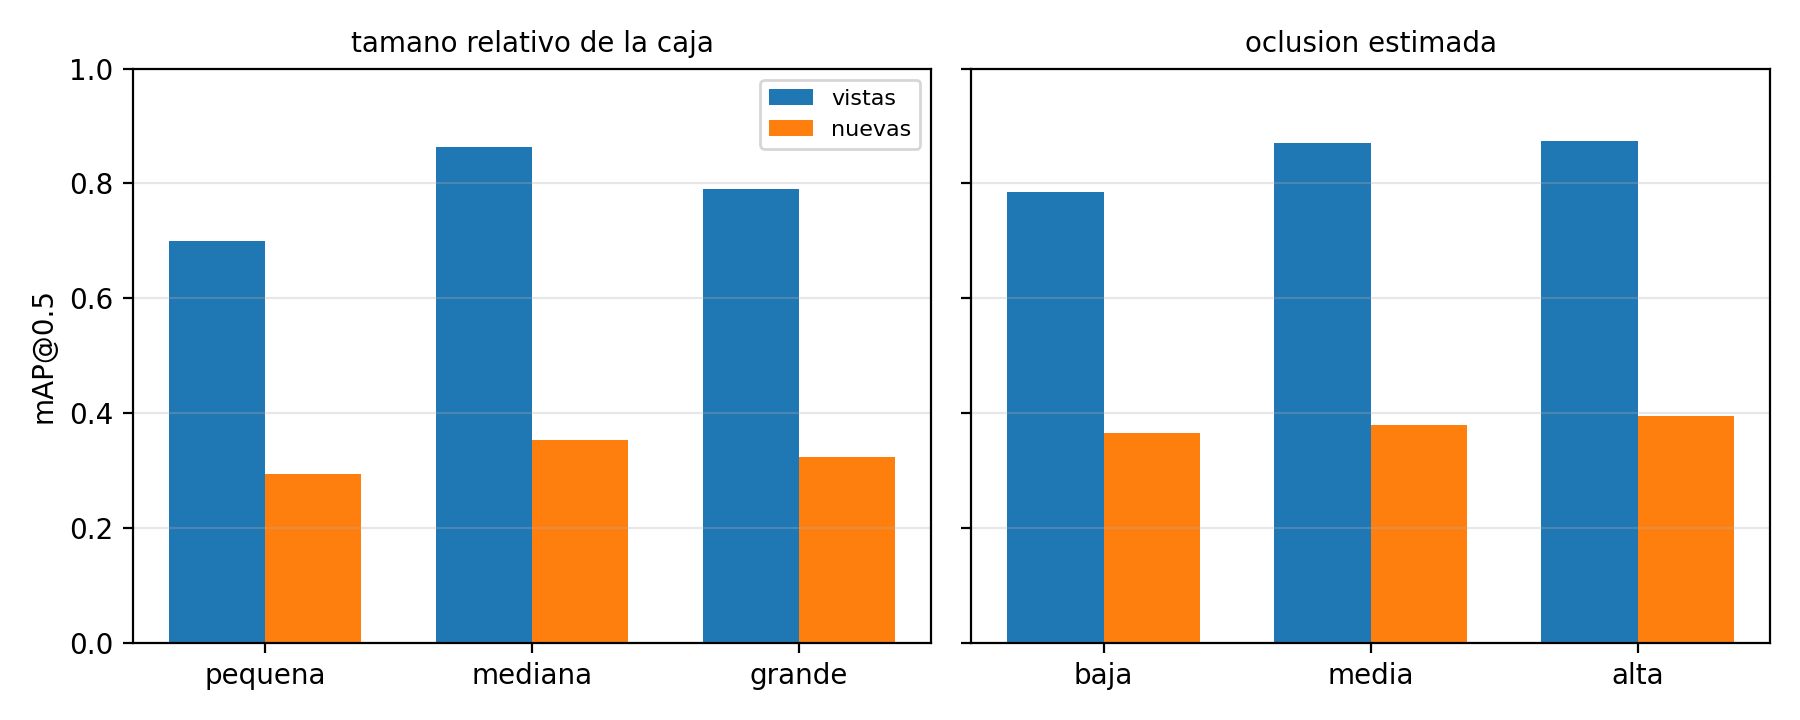

In [18]:
!python -m cct.robustness --config configs/config.yaml --weights {W} --set paths.reports={REP} paths.runs={RUNS}
display(pd.read_csv(f'{REP}/tables/robustness_drop.csv'))
display(Image(f'{REP}/figures/robustness_groups.png'))

## 9. Modulo de monitoreo ecologico, demo en una camara no vista (entregable 5)

 periodo  fotos  fotos_con_fauna  fotos_vacias  pct_fauna  pct_vacias  especies_distintas  detecciones
2010-W21    142              126            16  88.732394   11.267606                   5          129
2010-W22    202              182            20  90.099010    9.900990                   7          188
2010-W23    132              128             4  96.969697    3.030303                   5          139
2010-W24     52               49             3  94.230769    5.769231                   3           51
2010-W25     59               44            15  74.576271   25.423729                   5           48
2010-W26     44               42             2  95.454545    4.545455                   5           46
2010-W27     34               32             2  94.117647    5.882353                   3           32
2010-W28     40               38             2  95.000000    5.000000                   4           39
2010-W29     26               26             0 100.000000    0.000000    

,periodo,fotos,fotos_con_fauna,fotos_vacias,pct_fauna,pct_vacias,especies_distintas,detecciones
0,2010-W21,142,126,16,88.732394,11.267606,5,129
1,2010-W22,202,182,20,90.099010,9.900990,7,188
2,2010-W23,132,128,4,96.969697,3.030303,5,139
3,2010-W24,52,49,3,94.230769,5.769231,3,51
4,2010-W25,59,44,15,74.576271,25.423729,5,48
5,2010-W26,44,42,2,95.454545,4.545455,5,46
6,2010-W27,34,32,2,94.117647,5.882353,3,32
7,2010-W28,40,38,2,95.000000,5.000000,4,39
8,2010-W29,26,26,0,100.000000,0.000000,5,27
9,2010-W30,35,32,3,91.428571,8.571429,7,37


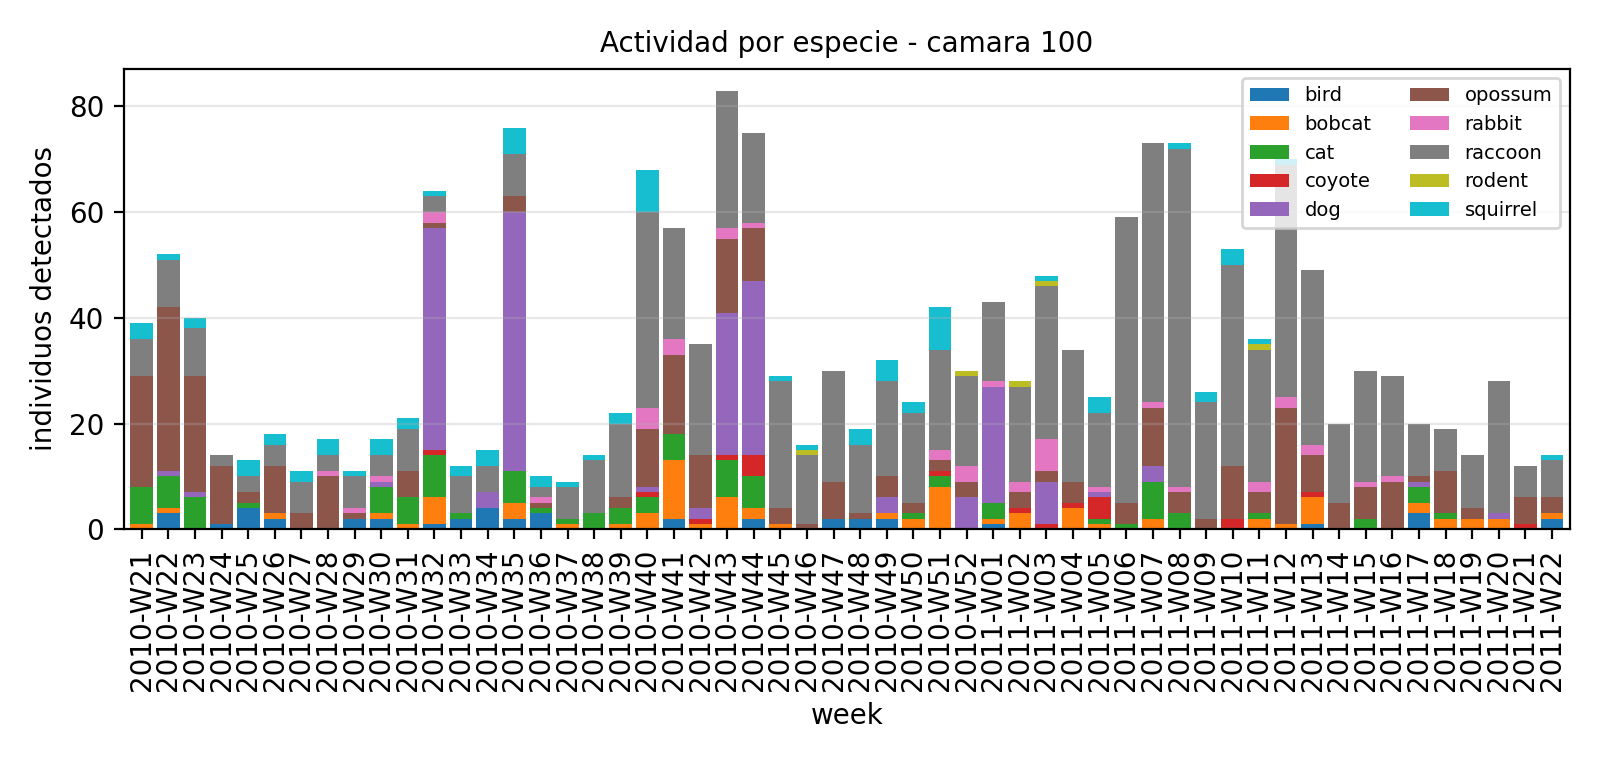

In [20]:
!python -m cct.monitoring --config configs/config.yaml --weights {W} --period week --set paths.reports={REP} paths.runs={RUNS}
import glob
for f in glob.glob(f'{REP}/monitoring/*_summary_week.csv'): display(pd.read_csv(f))
for f in glob.glob(f'{REP}/monitoring/*_activity_week.png'): display(Image(f))

## 10. Empaquetar resultados
Todo ya esta en Drive (`cct_yolo_out/`). Descarga `reports/` para pegar tablas y figuras en el informe.

In [21]:
!cd /content/drive/MyDrive/cct_yolo_out && zip -qr reports.zip reports && ls -la reports.zip

-rw------- 1 root root 10034104 Oct 30 08:48 reports.zip
